# 03 — Supervised Baseline Preparation

> **Can a transparent text classifier flag potentially high-risk complaints for review?**

| | |
|---|---|
| **Audience** | Data scientists, MLOps reviewers |
| **Owner** | CX Complaint Intelligence team |
| **Status** | Reference implementation (portfolio sample) |
| **Last reviewed** | 2026-05-25 |
| **Runtime** | ~20 s on the bundled sample |
| **Reproduces from** | `data/raw/cfpb_sample.csv` |

## Business question

Can we train a small, interpretable text baseline to prioritise high-risk complaints, and what does it learn about the language of high-risk cases?

## How to read this notebook

1. Section **0** initialises the environment and loads data.
2. Sections **1-N** build the analysis tables and visuals.
3. The **Insights** section is generated from the computed tables &mdash; it does not contain hand-written claims.
4. The **Limitations** section flags known caveats before stakeholders act on the numbers.
5. The **Exports** section persists every table and figure under `reports/notebook/03/` so the output is auditable.


## 0. Setup

This cell:

- locates the project root from wherever the kernel was started;
- applies the shared matplotlib house style and pandas display options;
- creates the artefact directory `reports/notebook/03/`;
- captures the Python and library versions used for this run.


In [1]:
from __future__ import annotations

import warnings
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cx_complaints.reports.notebook_utils import (
    PALETTE,
    RISK_COLORS,
    concentration_table,
    horizontal_bar,
    kpi_table,
    load_complaints,
    load_pipeline_outputs,
    monthly_summary,
    render_environment,
    save_figure,
    save_table,
    setup_notebook,
    topic_labels,
    write_environment_snapshot,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ctx = setup_notebook("03")
render_environment(ctx)


,field,value
0,python,3.12.11
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.4.6
3,pandas,2.3.3
4,matplotlib,3.10.9
5,scikit-learn,1.8.0
6,project_root,C:\Users\diogo\work_code\portfolio\cx-complain...
7,notebook_id,03


## 1. Build the labelled modelling dataset

In [2]:
from cx_complaints.modelling.supervised import (
    summarize_class_imbalance,
    time_aware_train_test_split,
)

complaints = load_complaints(ctx)
complaints["is_high_risk"] = (complaints["risk_level"] == "high").astype(int)
complaints[[
    "date_received", "clean_text", "risk_level", "is_high_risk",
]].head()

,date_received,clean_text,risk_level,is_high_risk
0,2024-06-21 12:00:00-05:00,"To Whom this may concern, I am writing to disp...",high,1
1,2024-06-18 12:00:00-05:00,On [REDACTED] / [REDACTED] /year> I was gettin...,medium,0
2,2024-06-14 12:00:00-05:00,"To Whom It May Concern, This Is my Third writt...",medium,0
3,2024-06-25 12:00:00-05:00,I have submitted multiple disputes regarding t...,medium,0
4,2024-06-28 12:00:00-05:00,I understand the significance of eliminating a...,medium,0


## 2. Time-aware train/test split

In [3]:
split = time_aware_train_test_split(
    frame=complaints, date_column="date_received", train_fraction=0.8,
)
print(f"Train rows: {len(split.train):,}")
print(f"Test rows:  {len(split.test):,}")
print(f"Split at:   {split.split_timestamp.date()}")

Train rows: 800
Test rows:  200
Split at:   2024-06-24


## 3. Class imbalance in the training set

In [4]:
summarize_class_imbalance(split.train["is_high_risk"])

,class_label,count,share_pct
0,0,690,86.25
1,1,110,13.75


## 4. Fit a transparent logistic-regression baseline

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from cx_complaints.modelling.supervised import evaluate_binary_classifier

pipeline = Pipeline([
    ("vectorizer", TfidfVectorizer(min_df=3, max_features=3000, ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])
pipeline.fit(split.train["clean_text"].fillna(""), split.train["is_high_risk"])

predicted = pd.Series(
    pipeline.predict(split.test["clean_text"].fillna("")), index=split.test.index,
)
probability = pd.Series(
    pipeline.predict_proba(split.test["clean_text"].fillna(""))[:, 1],
    index=split.test.index,
)
metrics = evaluate_binary_classifier(
    y_true=split.test["is_high_risk"], y_pred=predicted, y_score=probability,
)
metrics

BinaryMetrics(precision=0.42857142857142855, recall=0.9230769230769231, f1=0.5853658536585366, roc_auc=0.9339080459770115)

## 5. Interpretation: top positive and negative tokens

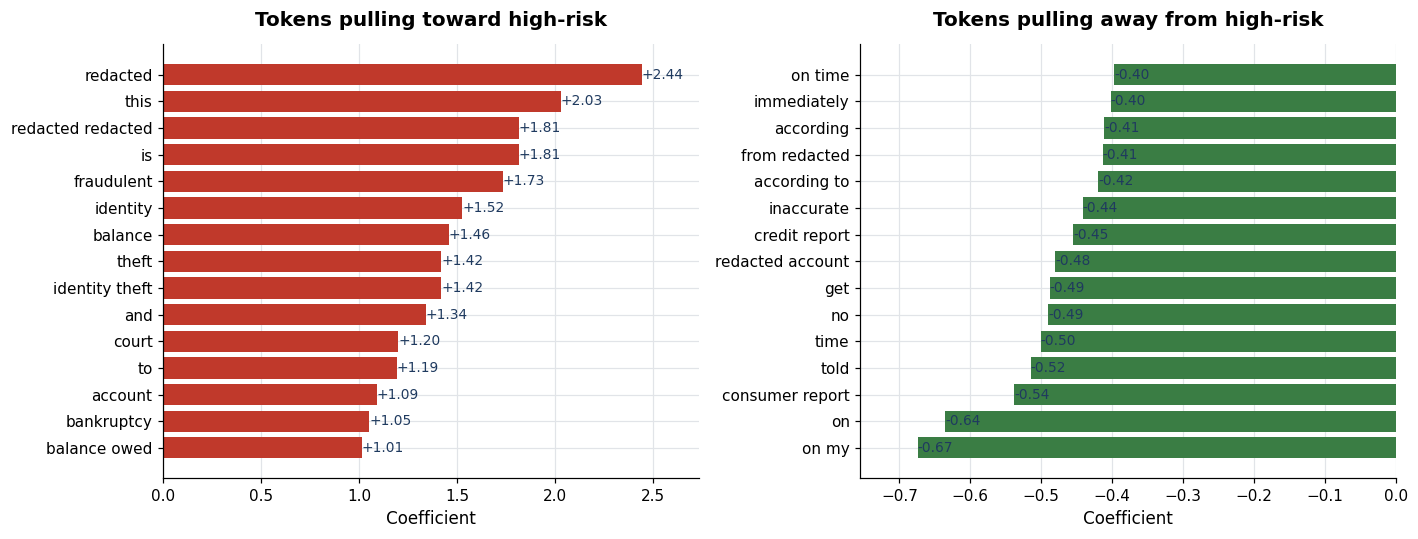

In [6]:
vectorizer = pipeline.named_steps["vectorizer"]
classifier = pipeline.named_steps["classifier"]
coefficients = pd.DataFrame({
    "feature": vectorizer.get_feature_names_out(),
    "coefficient": classifier.coef_[0],
})
positive = coefficients.sort_values("coefficient", ascending=False).head(15).reset_index(drop=True)
negative = coefficients.sort_values("coefficient", ascending=True).head(15).reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
horizontal_bar(axes[0], positive["feature"], positive["coefficient"], color=PALETTE["warning"], value_format="{:+.2f}")
axes[0].set_title("Tokens pulling toward high-risk")
axes[0].set_xlabel("Coefficient")
horizontal_bar(axes[1], negative["feature"], negative["coefficient"], color=PALETTE["positive"], value_format="{:+.2f}")
axes[1].set_title("Tokens pulling away from high-risk")
axes[1].set_xlabel("Coefficient")
fig.tight_layout()
save_figure(ctx, fig, "logreg_coefficient_extremes")
plt.show()

## 6. Insights

In [7]:
roc_text = f", ROC-AUC **{metrics.roc_auc:.2f}**" if metrics.roc_auc is not None else ""
narrative = "\n".join([
    f"- **Baseline performance**: precision **{metrics.precision:.2f}**, "
    f"recall **{metrics.recall:.2f}**, F1 **{metrics.f1:.2f}**{roc_text}.",
    f"- **Top positive token**: `{positive.iloc[0]['feature']}` "
    f"(coef {positive.iloc[0]['coefficient']:+.2f}).",
    f"- **Top negative token**: `{negative.iloc[0]['feature']}` "
    f"(coef {negative.iloc[0]['coefficient']:+.2f}).",
    "- **Caveat**: the label is the heuristic `risk_level == high`, not a validated outcome. "
    "The model therefore mostly recovers the heuristic's vocabulary &mdash; useful for "
    "prioritisation but not a substitute for analyst review.",
])
display(Markdown(narrative))

- **Baseline performance**: precision **0.43**, recall **0.92**, F1 **0.59**, ROC-AUC **0.93**.
- **Top positive token**: `redacted` (coef +2.44).
- **Top negative token**: `on my` (coef -0.67).
- **Caveat**: the label is the heuristic `risk_level == high`, not a validated outcome. The model therefore mostly recovers the heuristic's vocabulary &mdash; useful for prioritisation but not a substitute for analyst review.

## Limitations

- The risk score is heuristic, not a legal or regulatory finding. It exists to triage analyst attention.
- CFPB narratives are only published when the consumer consents, so coverage is partial.
- Company-level comparisons mix companies of very different sizes &mdash; always pair them with volume context.
- The sample bundled with this repo is a small subset of the public CFPB dataset and is meant for demonstration, not production decisions.

## Exports

All tables and figures generated above are saved under `reports/notebook/03/`. The environment snapshot is written alongside so a reader can reproduce the run.


In [8]:
save_table(ctx, positive, "logreg_top_positive_tokens")
save_table(ctx, negative, "logreg_top_negative_tokens")
save_table(
    ctx,
    pd.DataFrame([metrics.__dict__]),
    "logreg_test_metrics",
)
write_environment_snapshot(ctx)
sorted(ctx.artefact_dir.iterdir())

[WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/03/environment.json'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/03/logreg_coefficient_extremes.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/03/logreg_test_metrics.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/03/logreg_top_negative_tokens.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/03/logreg_top_positive_tokens.csv')]